In [17]:
%load_ext autoreload
%autoreload 2

In [18]:
import os
import torch.backends.cudnn as cudnn
import torch
import torchvision
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import cv2

#from pytorch_grad_cam import GradCAM
#from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
#from pytorch_grad_cam.utils.image import show_cam_on_image
import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution, GuidedGradCam
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz



sys.path.append('../../MARS')
sys.path.append('../../MARS/run_lars/code_3d')


#from MARS.run_lars.code_3d.dataset import get_datasets, dataset_center
from MARS.run_lars.code_3d.utils import model_prediction, my_model, modify_resnet_to_accomodate_two_channels

from MARS.run_lars.code_3d.dataset import dataset_3d, dataset_3d_center, get_datasets_3d
import h5py
import nibabel as nib
from totalsegmentator.python_api import totalsegmentator

In [19]:
color_dict = {}
np.random.seed(2025)
for i in range(255):
    color = tuple(np.random.randint(0, 255, size=3).tolist())
    color_dict[i] = color
color_dict[0] = (0, 0, 0)  # background as black

In [20]:
def load_h5_arr(file):
    h5 = h5py.File(file, 'r')
    arr = h5['image'][:]
    h5.close()
    return arr


In [21]:
bone_labels = list(range(25, 51)) + list(range(69,79)) + list(range(91,117))
tasks = ['total', 'vertebrae_body', 'appendicular_bones']

rois = [
"sacrum",
"vertebrae_S1",	"vertebrae_L5","vertebrae_L4","vertebrae_L3","vertebrae_L2","vertebrae_L1",
"vertebrae_T12","vertebrae_T11","vertebrae_T10","vertebrae_T9","vertebrae_T8","vertebrae_T7",
"vertebrae_T6","vertebrae_T5","vertebrae_T4","vertebrae_T3","vertebrae_T2","vertebrae_T1","vertebrae_C7","vertebrae_C6","vertebrae_C5","vertebrae_C4","vertebrae_C3",
"vertebrae_C2","vertebrae_C1",
"humerus_left",
"humerus_right",
"scapula_left",
"scapula_right",
"clavicula_left",
"clavicula_right",
"femur_left",
"femur_right",	
"hip_left",
"hip_right",
"skull",
"rib_left_1",
"rib_left_2",
"rib_left_3",
"rib_left_4",
"rib_left_5",
"rib_left_6",
"rib_left_7",
"rib_left_8",
"rib_left_9",
"rib_left_10",
"rib_left_11",
"rib_left_12",
"rib_right_1",
"rib_right_2",
"rib_right_3",
"rib_right_4",
"rib_right_5",
"rib_right_6",
"rib_right_7",
"rib_right_8",
"rib_right_9",
"rib_right_10",
"rib_right_11",
"rib_right_12"
]


In [22]:
full_data_csv = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan.csv')
#


/tmp/ipykernel_804532/1581244710.py:1: DtypeWarning: Columns (59) have mixed types. Specify dtype option on import or set low_memory=False.
  full_data_csv = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan.csv')


In [23]:
# load h5 file
#file = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/3150912/3150912_ct_1.h5'
file = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5_aligned_ct/3150912/3150912_ct_0.h5'
search_fullpath = file.split('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5_aligned_ct/')[1]
row = full_data_csv[full_data_csv['fullfile'] == search_fullpath]
sz_x = row['pixel_size_1'].values[0]
sz_y = row['pixel_size_2'].values[0]
sz_z = row['pixel_size_3'].values[0]

# change to be PT pixel sizes
sz_x = 4.0638856390552
sz_y = 4.0638856390552


affine_arr = np.array([ [sz_x, 0, 0, 0],
                        [0, sz_y, 0, 0],
                        [0, 0, sz_z, 0],
                        [0, 0, 0, 1]])

arr = load_h5_arr(file)

new_image = nib.Nifti1Image(arr, affine=affine_arr)

# union all tasks

unioned_segmentation = np.zeros(arr.shape)
for task in tasks:
    if task == 'total':
        segmented = totalsegmentator(new_image, task = task, roi_subset = rois)
    else:
        segmented = totalsegmentator(new_image, task = task)
    
    unioned_segmentation = np.maximum(unioned_segmentation, segmented.get_fdata() > 0)
    

KeyboardInterrupt: 

In [ ]:
plt.imshow(unioned_segmentation[75,:,:], cmap='gray')
plt.savefig('/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/tsto2.png')

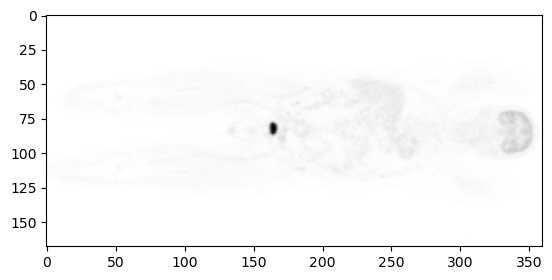

In [ ]:
file = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/3150912/3150912_pt_0.h5'
arr = load_h5_arr(file)
plt.imshow(arr[75,:,:], cmap='gray_r')
plt.savefig('/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/tsto3.png')

In [ ]:
arr2_v = np.zeros_like(arr2)
for label in bone_labels:
   arr2_v[segmented.get_fdata() == label] = label

In [ ]:
arr2_v = arr2

In [ ]:
arr2_v = unioned_segmentation

In [ ]:
pet = load_h5_arr('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/3150912/3150912_pt_0.h5')
print('CT Shape:', arr.shape)
print(f'CT values: {np.min(arr)}, {np.max(arr)}')
print('Segmented Shape:', arr2.shape)
print('PET Shape:', pet.shape)

CT Shape: (512, 512, 360)
CT values: -1024.0, 3071.0
Segmented Shape: (512, 512, 360)
PET Shape: (168, 168, 360)


In [ ]:
print('CT Shape:', arr.shape)
print(f'CT values: {np.min(arr)}, {np.max(arr)}')
print('Segmented Shape:', arr2.shape)
print('PET Shape:', pet.shape)

CT Shape: (512, 512, 360)
CT values: -1024.0, 3071.0
Segmented Shape: (512, 512, 360)
PET Shape: (168, 168, 360)


In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(10,5))
idx = 250
axis = 2
pet_idx = idx * pet.shape[axis] // arr.shape[axis] 

axs[0].imshow(arr.take(indices=idx, axis=axis), cmap='gray')

# use color dict to color the segmentation mask
segmented_image = np.zeros((*arr2_v.take(indices=idx, axis=axis).shape, 3), dtype=np.uint8)
for label, color in color_dict.items():
    segmented_image[arr2_v.take(indices=idx, axis=axis) == label] = color
axs[1].imshow(segmented_image)
axs[2].imshow(pet.take(indices=pet_idx, axis=axis), cmap='gray')
#fig.show()
plt.savefig('/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/segmented_slice.png')

In [ ]:
plt.figure()
plt.imshow(pet[100,:,:])
plt.savefig('/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/segslc2.png')

In [ ]:
# save the original CT nifti to a nii.gz file
nib.save(nib.Nifti1Image(arr, affine=np.eye(4)), '/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/original_ct.nii.gz')

In [ ]:
# how many 
cur_df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_curated.csv')

In [ ]:
cur_df

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,corrections,pixel_unit,frame_duration,tracer,tracer_injection_time,tracer_dose,tracer_halflife,image_filter,contrast_route,axial_fov
0,10002388,10002388_pt_0.h5,10002388_pt_0.pkl,10002388/10002388_pt_0.h5,081Y,M,106.594221,UNKNOWN,10002388,1.2.840.114350.2.232.2.798268.2.86568933.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,105100.0,5.953300e+08,6586.2,NaN,NaN,1860.00
1,10024518,10024518_pt_0.h5,10024518_pt_0.pkl,10024518/10024518_pt_0.h5,059Y,M,130.000000,NaN,10024518,1.2.840.113619.2.55.3.2550794926.409.143108503...,...,DECY|ATTN|SCAT|DTIM|RAN|DCAL|SLSENS|NORM,BQML,120000.0,FDG -- fluorodeoxyglucose,101100.0,4.922128e+08,6588.0,NaN,NaN,1095.45
2,10032528,10032528_pt_1.h5,10032528_pt_1.pkl,10032528/10032528_pt_1.h5,045Y,F,67.585272,NaN,10032528,1.3.12.2.1107.5.1.4.11052.30000015051113231648...,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,81600.0,5.513000e+08,6586.2,NaN,NaN,852.00
3,10050499,10050499_pt_0.h5,10050499_pt_0.pkl,10050499/10050499_pt_0.h5,065Y,M,143.788800,UNKNOWN,10050499,1.2.840.114350.2.232.2.798268.2.88694207.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,105500.0,5.871900e+08,6586.2,NaN,NaN,1983.00
4,10057383,10057383_pt_0.h5,10057383_pt_0.pkl,10057383/10057383_pt_0.h5,056Y,F,79.832267,UNKNOWN,10057383,1.2.840.114350.2.232.2.798268.2.88519269.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,85700.0,5.598100e+08,6586.2,NaN,NaN,1860.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1558,9969440,9969440_pt_0.h5,9969440_pt_0.pkl,9969440/9969440_pt_0.h5,058Y,M,64.410125,UNKNOWN,9969440,1.2.840.114350.2.232.2.798268.2.86232892.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,90800.0,5.287300e+08,6586.2,NaN,NaN,1860.00
1559,9969540,9969540_pt_0.h5,9969540_pt_0.pkl,9969540/9969540_pt_0.h5,069Y,M,77.110713,UNKNOWN,9969540,1.2.840.114350.2.232.2.798268.2.86232954.1,...,NORM|DTIM|ATTN|SCAT|DECY|RAN,BQML,120000.0,Fluorodeoxyglucose,73600.0,5.709100e+08,6586.2,NaN,NaN,1860.00
1560,9971489,9971489_pt_0.h5,9971489_pt_0.pkl,9971489/9971489_pt_0.h5,062Y,F,60.327793,NaN,9971489,1.2.840.114350.2.232.2.798268.2.80532574.1,...,NORM|DTIM|ATTN|SCAT|RADL|DECY,BQML,120000.0,FDG,120500.0,5.772000e+08,6586.2,NaN,NaN,1675.00
1561,9988177,9988177_pt_0.h5,9988177_pt_0.pkl,9988177/9988177_pt_0.h5,072Y,F,70.370000,UNKNOWN,9988177,1.2.840.114350.2.232.2.798268.2.86811327.1,...,RAN|DTIM|NORM|ATTN|SCAT|DECY,BQML,120000.0,NaN,140000.0,5.291000e+08,6586.2,NaN,NaN,1675.00


In [ ]:
xx = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan.csv')
xx = xx[xx['modality'] == 'CT'][['filepath', 'filename', 'fullfile', 'scan_date', 'description_series', 'matrix_size_1', 'matrix_size_2', 'matrix_size_3', 'pixel_size_1', 'pixel_size_2', 'pixel_size_3']].reset_index(drop=True)

# print unique filepaths
print(len(xx['filepath'].unique()))

# merge in the cur_df['matrix_size_3']
xx = xx.merge(cur_df[['filepath', 'matrix_size_3', 'pixel_size_1', 'pixel_size_2', 'pixel_size_3']], on='filepath', how='left')
# and filter out na's
xx = xx[~xx['matrix_size_3_y'].isna()].reset_index(drop=True)

# print unique filepaths
print(len(xx['filepath'].unique()))


# filter for scans with 'AC_CT' or 'AC CT' in description series
yy = xx

# subset xx to all rows where description_series contains 'AC CT' or 'AC_CT'
xx = xx[xx['description_series'].str.contains(f'CT|Standard|I 40f medium C+|B 40 S MEDIUM', case=False)].reset_index(drop=True)

st2 = set(xx['filepath'].values)
# print unique filepaths
print(len(xx['filepath'].unique()))

# next, filter for scans where matrix_size_3_x == matrix_size_3_y

# now, for each unique filepath, pick the row with matrix_size_3_y closest to matrix_size_3_x
xx['matrix_size_3_y'] = xx['matrix_size_3_y'].astype(float)
xx['matrix_size_3_x'] = xx['matrix_size_3_x'].astype(float)
xx['matrix_size_3_diff'] = (xx['matrix_size_3_x'] - xx['matrix_size_3_y']).abs()
idx = xx.groupby('filepath')['matrix_size_3_diff'].idxmin()
xx = xx.loc[idx].reset_index(drop=True)

'''
xx = xx[xx['matrix_size_3_x'] == xx['matrix_size_3_y']].reset_index(drop=True)

# print unique filepaths
'''
st3 = set(xx['filepath'].values)
print(len(xx['filepath'].unique()))

3240
1562
1562
1562


/tmp/ipykernel_804532/2223697308.py:1: DtypeWarning: Columns (59) have mixed types. Specify dtype option on import or set low_memory=False.
  xx = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan.csv')


In [ ]:
xx.to_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_filtered_for_ct_segmentation.csv', index=False)

In [ ]:
xx

,filepath,filename,fullfile,scan_date,description_series,matrix_size_1,matrix_size_2,matrix_size_3_x,pixel_size_1_x,pixel_size_2_x,pixel_size_3_x,matrix_size_3_y,pixel_size_1_y,pixel_size_2_y,pixel_size_3_y,matrix_size_3_diff
0,2938443,2938443_ct_1.h5,2938443/2938443_ct_1.h5,20050729,AC_CT VERTEX TO ANKLES,512.0,512.0,331.0,1.367188,1.367188,4.0,331.0,4.063886,4.063886,4.0,0.0
1,3150912,3150912_ct_0.h5,3150912/3150912_ct_0.h5,20060209,AC_CT VERTEX TO ANKLES,512.0,512.0,360.0,1.367188,1.367188,4.0,360.0,4.063886,4.063886,4.0,0.0
2,3602197,3602197_ct_0.h5,3602197/3602197_ct_0.h5,20070323,AC_CT VERTEX TO ANKLES,512.0,512.0,389.0,1.367188,1.367188,4.0,389.0,4.063886,4.063886,4.0,0.0
3,3808667,3808667_ct_1.h5,3808667/3808667_ct_1.h5,20070925,B 40 S MEDIUM,512.0,512.0,219.0,0.830078,0.830078,5.0,219.0,4.063886,4.063886,5.0,0.0
4,4134295,4134295_ct_1.h5,4134295/4134295_ct_1.h5,20080215,B 40 S MEDIUM,512.0,512.0,219.0,0.802734,0.802734,5.0,219.0,4.063886,4.063886,5.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1557,43561254,43561254_ct_0.h5,43561254/43561254_ct_0.h5,20240612,AC CT 4.0 HD_FoV iMAR,512.0,512.0,389.0,1.523438,1.523438,4.0,389.0,1.650000,1.650000,4.0,0.0
1558,43608032,43608032_ct_1.h5,43608032/43608032_ct_1.h5,20240605,CT WB,512.0,512.0,622.0,0.976562,0.976562,3.0,622.0,4.072840,4.072840,3.0,0.0
1559,43644283,43644283_ct_0.h5,43644283/43644283_ct_0.h5,20240606,CT WB,512.0,512.0,308.0,0.976562,0.976562,3.0,308.0,4.072840,4.072840,3.0,0.0
1560,43668564,43668564_ct_0.h5,43668564/43668564_ct_0.h5,20240611,AC CT 4.0 HD_FoV,512.0,512.0,247.0,1.523438,1.523438,4.0,247.0,1.650000,1.650000,4.0,0.0


In [ ]:
# now write it with the updated CT h5s
# just need to change pixel_size
xx = xx.drop(['pixel_size_1_x', 'pixel_size_2_x', 'pixel_size_3_x'], axis=1)
xx = xx.rename(columns={'pixel_size_1_y': 'pixel_size_1', 'pixel_size_2_y': 'pixel_size_2', 'pixel_size_3_y': 'pixel_size_3'})

In [24]:
xx.to_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_ct_filtered_for_segmentation_resampled_to_pet.csv', index=False)

In [ ]:
# load h5
file = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/ct_bone_segmentations/2938443/2938443_ct_1_bone_segmentation.h5'

with h5py.File(file, 'r') as h5:
    segmentation = h5['segmentation'][:]  

### Create linking between PET and CT

In [ ]:
# create linking between PET and CT
xx = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan_filtered_for_ct_segmentation.csv')

In [ ]:
xx

,filepath,filename,fullfile,scan_date,description_series,matrix_size_1,matrix_size_2,matrix_size_3_x,pixel_size_1,pixel_size_2,pixel_size_3,matrix_size_3_y,matrix_size_3_diff
0,2938443,2938443_ct_1.h5,2938443/2938443_ct_1.h5,20050729,AC_CT VERTEX TO ANKLES,512.0,512.0,331.0,1.367188,1.367188,4.0,331.0,0.0
1,3150912,3150912_ct_0.h5,3150912/3150912_ct_0.h5,20060209,AC_CT VERTEX TO ANKLES,512.0,512.0,360.0,1.367188,1.367188,4.0,360.0,0.0
2,3602197,3602197_ct_0.h5,3602197/3602197_ct_0.h5,20070323,AC_CT VERTEX TO ANKLES,512.0,512.0,389.0,1.367188,1.367188,4.0,389.0,0.0
3,3808667,3808667_ct_1.h5,3808667/3808667_ct_1.h5,20070925,B 40 S MEDIUM,512.0,512.0,219.0,0.830078,0.830078,5.0,219.0,0.0
4,4134295,4134295_ct_1.h5,4134295/4134295_ct_1.h5,20080215,B 40 S MEDIUM,512.0,512.0,219.0,0.802734,0.802734,5.0,219.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1557,43561254,43561254_ct_0.h5,43561254/43561254_ct_0.h5,20240612,AC CT 4.0 HD_FoV iMAR,512.0,512.0,389.0,1.523438,1.523438,4.0,389.0,0.0
1558,43608032,43608032_ct_1.h5,43608032/43608032_ct_1.h5,20240605,CT WB,512.0,512.0,622.0,0.976562,0.976562,3.0,622.0,0.0
1559,43644283,43644283_ct_0.h5,43644283/43644283_ct_0.h5,20240606,CT WB,512.0,512.0,308.0,0.976562,0.976562,3.0,308.0,0.0
1560,43668564,43668564_ct_0.h5,43668564/43668564_ct_0.h5,20240611,AC CT 4.0 HD_FoV,512.0,512.0,247.0,1.523438,1.523438,4.0,247.0,0.0


In [ ]:
# remove any rows whose path doesnt exist for fullfile_ct_bone_segmentation

In [ ]:
xx['fullfile']

0         2938443/2938443_ct_1.h5
1         3150912/3150912_ct_0.h5
2         3602197/3602197_ct_0.h5
3         3808667/3808667_ct_1.h5
4         4134295/4134295_ct_1.h5
                  ...            
1557    43561254/43561254_ct_0.h5
1558    43608032/43608032_ct_1.h5
1559    43644283/43644283_ct_0.h5
1560    43668564/43668564_ct_0.h5
1561    43804297/43804297_ct_1.h5
Name: fullfile, Length: 1562, dtype: object

In [ ]:
tdf['fullfile_ct_bone_segmentation'].apply(lambda x: os.path.exists(rta + x.replace('.h5', '_bone_segmentation.h5')))

Series([], Name: fullfile_ct_bone_segmentation, dtype: object)

In [ ]:
for tag in ['train', 'val', 'test']:
    print(tag)
    tdf = pd.read_csv(f'/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/{tag}_df.csv')
    print(len(tdf))

    # merge tdf with xx on filepath
    tdf = tdf.merge(xx[['filepath', 'fullfile', 'pixel_size_1', 'pixel_size_2', 'pixel_size_3']], on='filepath', how='left', suffixes=('', '_ct'))

    # now create new column for ct bone segmentation h5
    tdf['fullfile_ct_bone_segmentation'] = tdf['fullfile_ct'].str.replace('.h5', '_bone_segmentation.h5')

    # exclude any rows where fullfile_ct_bone_segmentation is na
    tdf = tdf[~tdf['fullfile_ct_bone_segmentation'].isna()].reset_index(drop=True)

    # exclude any rows where fullfile_ct_bone_segmentation path does not exist

    rta = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/ct_bone_segmentations/'
    tdf = tdf[tdf['fullfile_ct_bone_segmentation'].apply(lambda x: os.path.exists(rta + x))].reset_index(drop=True)

    print(len(tdf))

    #tdf.to_csv(f'/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/{tag}_df_with_ct_bone_segmentation.csv', index=False)
    tdf.to_csv(f'/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/{tag}_df_with_ct_bone_segmentation_TEMP.csv', index=False)

train
739
721
val
148
143
test
592
584


In [ ]:
# create dataset3d
data_path_img='/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5'
data_path='/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/train_df_with_ct_bone_segmentation.csv'

qq = get_datasets_3d(dataset_type = 'val', transform=None, norm=False, 
                     data_path_img=data_path_img, 
                     data_path=data_path, target_label_name='PET_jco', ct_mode = 'BONE_SEG', ct_bone_seg_dilation_erosion_pixels=7, ct_bone_seg_dilation_alone_pixels=50)

# get resnet model


In [ ]:
uu = qq[1]

(209, 209, 476)
torch.Size([1, 250, 250, 300])
(214, 214, 476)
torch.Size([1, 250, 250, 300])


In [ ]:
uu[0].shape

torch.Size([2, 250, 250, 300])

In [ ]:
model_path_pattern= "/gpfs/data/mayerhoeferlab/projects/lars/lars3d_chpt/LARS_trained_state-dict_0.pth"
model = model_prediction(model_path_pattern)

/gpfs/home/kn2347/MARS/notebooks/../../MARS/MARS/run_lars/code_3d/utils.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ch = torch.load(chpnt)


In [ ]:
model = modify_resnet_to_accomodate_two_channels(model)

In [ ]:
model.cuda()
model.eval()
ex = uu[0].unsqueeze(0).cuda()

In [ ]:
out = model(ex)

In [ ]:
out

tensor([[-42.3209,  41.9887]], device='cuda:0', grad_fn=<AddmmBackward0>)

### Figure out the right dilation-erosion parameters

In [ ]:
pp = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/val_df_with_ct_bone_segmentation_TEMP.csv')
pp[pp['filename_header'] == '8166597_pt_0.pkl']

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,image_filter,contrast_route,axial_fov,PET_jco,PET_imwg,fullfile_ct,pixel_size_1_ct,pixel_size_2_ct,pixel_size_3_ct,fullfile_ct_bone_segmentation
126,8166597,8166597_pt_0.h5,8166597_pt_0.pkl,8166597/8166597_pt_0.h5,062Y,M,96.702,NaN,8166597,1.3.12.2.1107.5.1.4.44843.30000013031112400792...,...,NaN,NaN,975.0,1.0,1.0,8166597/8166597_ct_0.h5,1.367188,1.367188,5.0,8166597/8166597_ct_0_bone_segmentation.h5


In [ ]:
vol.shape

(250, 250, 300)

In [ ]:
vol.shape

(2, 250, 250, 300)

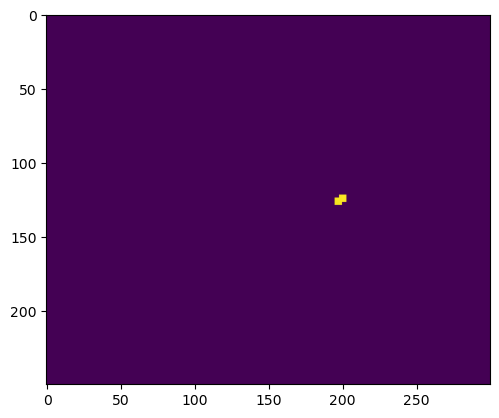

In [ ]:
plt.imshow(img)

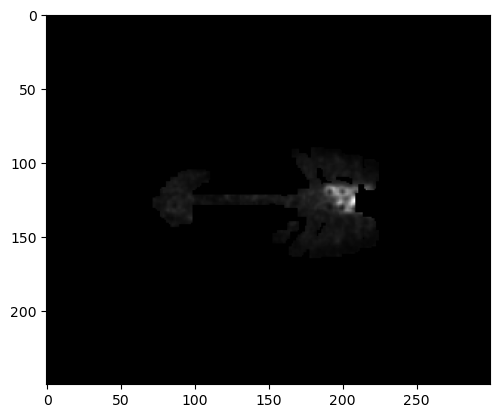

In [ ]:
plt.imshow(vol[1,162,:,:], cmap='gray')

In [ ]:
# 10 -> 4 is reasonable?
# get an example 3d image with bone segmentation
# create dataset3d

data_path_img='/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5'
data_path='/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/val_df_with_ct_bone_segmentation_TEMP.csv'

#fig, axs = plt.subplots(1, 6, figsize=(20,5))

qq = get_datasets_3d(dataset_type = 'val', transform=None, norm=False, 
                        data_path_img=data_path_img, 
                        data_path=data_path, target_label_name='PET_jco', ct_mode = 'BONE_SEG_MASK_MULTIPLY', ct_bone_seg_dilation_erosion_pixels=7, ct_bone_seg_dilation_alone_pixels=10)
vv = qq[126]
vol = vv[0][:,:,:,:].numpy()

# make gif out of channel 0 of vv
# with channel 1 as an overlaid contour
import imageio

images = []
for j in range(vol.shape[1]):
    if np.sum(vol[1,j,:,:]) == 0:
        continue

    #img = (vol[1, j,:,:] - np.min(vol)) / (np.max(vol) - np.min(vol)) * 255.0
    img = img.astype(np.uint8)
    #img = 255 - img

    # multiply img by binary channel 1
    #img = img * vol[1, j,:,:].astype(np.uint8)

    # overlay contour of channel 1
    #contour = vol[1, j,:,:]
    #contour = (contour > 0).astype(np.uint8) * 255
    #contours, _ = cv2.findContours(contour, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    #cv2.drawContours(img, contours, -1, (255, 0, 0), 1)

    images.append(img)

    # use channel 1 as contour
imageio.mimsave(f'/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/ct_bone_seg_dilation_erosion.gif', images, fps=10)




# save gif of vol sliding through axis 0

# images = []
# for j in range(vol.shape[0]):
#     if np.sum(vol[j,:,:]) == 0:
#         continue
#     img = (vol[j,:,:] - np.min(vol)) / (np.max(vol) - np.min(vol)) * 255.0
#     img = img.astype(np.uint8)
#     images.append(255 - img)
# imageio.mimsave(f'/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/ct_bone_seg_dilation_erosion_{szs[i]}.gif', images, fps=10)

    #axs[i].imshow(np.rot90(vv[0][1,100,:,:]), cmap='gray_r')
    #axs[i].set_title(f"sz: {szs[i]}")
#fig.show()

In [ ]:
vv = qq[0]

In [ ]:
vv[0][1,125,:,:].min()

tensor(0.)

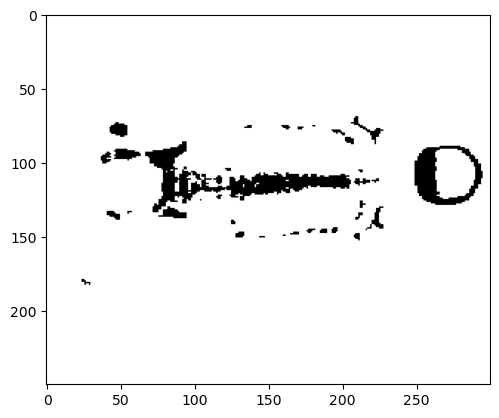

In [ ]:
plt.imshow(vv[0][1,100,:,:], cmap='gray_r')